In [7]:
import numpy as np
from pathlib import Path
import tensorflow as tf
from PIL import Image
from hailo_sdk_client import ClientRunner, InferenceContext
import matplotlib.pyplot as plt
import os
import yaml
import cv2
from hailo_sdk_client.sdk_backend.sdk_backend import SDKPaths

# Monkey-patch đè thuộc tính is_release thành True
SDKPaths.is_release = property(lambda self: True)

os.environ["USER"] = "root"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["TF_RAM_ALLOCATOR_BYTES_LIMIT"] = "3221225472"
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"



In [2]:
hailo_working_dir=Path("/home/duykhongcay/hailo_ws/chess_pieces_detection/runs/chess_detection_yolo11n-2/hailo_chesspieces_model-2")

# Configuration parameters
chosen_hw_arch = "hailo8"  # Options: 'hailo8', 'hailo8r', etc.
model_name="yolo11n"

IMAGES_TO_VISUALIZE=5
# Initialize ClientRunner with the target hardware architecture
runner = ClientRunner(hw_arch=chosen_hw_arch)


In [9]:
onnx_path = Path("/home/duykhongcay/hailo_ws/chess_pieces_detection/runs/chess_detection_yolo11n-2/hailo_chesspieces_model-2/best.onnx")
dataset_yaml_path=Path("/home/duykhongcay/hailo_ws/chess_pieces_detection/datasets/rbflow_chesspieces_dataset/data.yaml")
images_path = Path("/home/duykhongcay/hailo_ws/chess_pieces_detection/datasets/rbflow_chesspieces_dataset/train/images")

native_model_har_path = str(hailo_working_dir/f"{model_name}_hailo_model.har")
optimized_model_har_path=str(hailo_working_dir/f"{model_name}_optimized_model.har")
quantized_model_har_path=str(hailo_working_dir/f"{model_name}_quantized_model.har")
compiled_model_har_path=str(hailo_working_dir/f"{model_name}_compiled_model.har")
hef_path=str(hailo_working_dir/f"{model_name}.hef")
runtime_data_path=str(hailo_working_dir/f"runtime_data_{model_name}.json")

### Step 0: Parse ONNX Model to HAR File
Translate the ONNX model into Hailo Archive (HAR) format using `ClientRunner.translate_onnx_model` and save the parsed HAR file.

In [ ]:
from hailo_sdk_client.model_translator.exceptions import ParsingWithRecommendationException

# Translate ONNX model to Hailo internal graph representation (HN) & weights (NPZ)
# Note: Add start_node_names, end_node_names, or net_input_shapes if original model has dynamic axes
hn, npz = runner.translate_onnx_model(
    model=onnx_path,
    net_name=model_name,
    # start_node_names=["images"],
    end_node_names=[
        "/model.23/cv2.0/cv2.0.2/Conv",
        "/model.23/cv2.1/cv2.1.2/Conv",
        "/model.23/cv2.2/cv2.2.2/Conv",
        "/model.23/cv3.0/cv3.0.2/Conv",
        "/model.23/cv3.1/cv3.1.2/Conv",
        "/model.23/cv3.2/cv3.2.2/Conv",
    ],
)

# Define model script commands (normalization + NMS post-processing)
model_script= [
    "normalization1 = normalization([0.0, 0.0, 0.0], [255.0, 255.0, 255.0])\n",
    "nms_postprocess(meta_arch=yolov8, engine=cpu, nms_scores_th=0.25, nms_iou_th=0.65, classes=12)\n",
    "model_optimization_flavor(optimization_level=1, batch_size=1)\n",
]
runner.load_model_script("".join(model_script))
# Save the parsed floating-point model state to HAR (Hailo Archive)
runner.save_har(native_model_har_path)

[info] Translation started on ONNX model yolo11n
[info] Restored ONNX model yolo11n (completion time: 00:00:00.05)
[info] Extracted ONNXRuntime meta-data for Hailo model (completion time: 00:00:00.22)
[info] Start nodes mapped from original model: 'images': 'yolo11n/input_layer1'.
[info] End nodes mapped from original model: '/model.23/cv2.0/cv2.0.2/Conv', '/model.23/cv2.1/cv2.1.2/Conv', '/model.23/cv2.2/cv2.2.2/Conv', '/model.23/cv3.0/cv3.0.2/Conv', '/model.23/cv3.1/cv3.1.2/Conv', '/model.23/cv3.2/cv3.2.2/Conv'.
[info] Translation completed on ONNX model yolo11n (completion time: 00:00:00.89)
[info] Loading model script commands to yolo11n from string
[info] Saved HAR to: /home/duykhongcay/hailo_ws/chess_pieces_detection/runs/chess_detection_yolo11n-2/hailo_chesspieces_model-2/yolo11n_hailo_model.har


---------------------------
## Step 1: Test Native Model
Check the parsed floating-point native model using Hailo SDK emulator context.


## Step 2 & 3: Apply Model Modifications & Test Modified Model
Apply model script configurations (such as normalization layer) and test the full-precision modified model.
### Preliminary Step: Create Pre and Post Processing Functions

In [5]:
# Create Pre and Post Processing Functions

# -----------------------------------------
# Pre processing (prepare input images for YOLO)
# -----------------------------------------
def preproc(image, output_height=640, output_width=640, normalize=False):
    """Resize input image to YOLO input resolution and optionally normalize."""
    img_tensor = tf.cast(image, tf.float32)
    resized_image = tf.image.resize(img_tensor, [output_height, output_width])

    if normalize:
        # Scale pixel range from [0, 255] to [0.0, 1.0] for YOLO models
        resized_image = resized_image / 255.0

    return resized_image


# -----------------------------------------------------
# Post processing & Dataset Labels (YOLO format)
# -----------------------------------------------------
def _get_dataset_labels(yaml_path=dataset_yaml_path):
    """Load class names directly from YOLO dataset configuration file."""
    with open(yaml_path, 'r') as f:
            data_cfg = yaml.safe_load(f)
    return data_cfg.get('names', [])
    
dataset_labels = _get_dataset_labels()

def postproc(nms_output, imgsz=640):
    """Parse Hailo SDK emulator NMS output tensor into standard detection list format."""
    batch_detections = []

    # Unwrap dict format from Hailo SDK if returned
    if isinstance(nms_output, dict):
        nms_output = list(nms_output.values())[0]

    batch_size = nms_output.shape[0]
    num_classes = nms_output.shape[1]

    for i in range(batch_size):
        image_detections = []
        for class_idx in range(num_classes):
            scores = nms_output[i][class_idx, 4, :]
            boxes = nms_output[i][class_idx, 0:4, :] # Shape: (4, max_detections)
            class_name = dataset_labels[class_idx] if class_idx < len(dataset_labels) else str(class_idx)

            for det_idx in range(boxes.shape[1]):
                score = float(scores[det_idx])
                if score <= 0.0:
                    # Skip padded null detections
                    continue

                # Coordinates from NMS layer are normalized [ymin, xmin, ymax, xmax]
                y_min = float(boxes[0, det_idx] * imgsz)
                x_min = float(boxes[1, det_idx] * imgsz)
                y_max = float(boxes[2, det_idx] * imgsz)
                x_max = float(boxes[3, det_idx] * imgsz)

                image_detections.append({
                    "box": [x_min, y_min, x_max, y_max],
                    "conf": score,
                    "class_name": class_name
                })
        batch_detections.append(image_detections)

    return batch_detections


# -------------
# Visualization
# -------------
# Color palette for drawing YOLO bounding boxes (RGB format)
CLASS_COLORS = {
    "P": (100, 200, 255), "R": (0, 170, 255), "N": (0, 140, 255), 
    "B": (0, 100, 255),   "Q": (0, 50, 255),  "K": (100, 0, 255),
    "p": (255, 200, 100), "r": (255, 170, 0), "n": (255, 140, 0), 
    "b": (255, 100, 0),   "q": (255, 50, 0),  "k": (255, 0, 100),
}


def draw_yolo_detections(image_rgb, detections):
    """Draw YOLO bounding boxes, labels, confidence scores, and base reference points."""
    annotated = image_rgb.copy()
    img_h, img_w = annotated.shape[:2]
    base_offset_ratio = 0.15

    for det in detections:
        box = det["box"]
        x1, y1, x2, y2 = float(box[0]), float(box[1]), float(box[2]), float(box[3])
        cls_name = det.get("class_name", "P")
        conf = det.get("conf", 0.0)

        box_h = y2 - y1
        x_mid = (x1 + x2) / 2.0
        y_base = y2 - (box_h * base_offset_ratio)

        # Color mapping for chess pieces
        color_rgb = CLASS_COLORS.get(cls_name, (0, 255, 0))

        # 1. Draw bounding box rectangle
        cv2.rectangle(annotated, (int(x1), int(y1)), (int(x2), int(y2)), color_rgb, 2)

        # 2. Draw red dot at piece base reference point
        # cv2.circle(annotated, (int(x_mid), int(y_base)), 4, (255, 0, 0), -1)

        # 3. Draw confidence label bar
        label = f"{cls_name} {conf:.2f}"
        (label_w, label_h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)

        label_y1 = max(int(y1) - label_h - 4, 0)
        cv2.rectangle(annotated, (int(x1), label_y1), (int(x1) + label_w + 4, label_y1 + label_h + 4), color_rgb, -1)
        cv2.putText(
            annotated, label, (int(x1) + 2, label_y1 + label_h + 1),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA
        )

    return annotated


def visualize_results(images, batch_detections, title="YOLO Bounding Box", return_history=False):
    """Display and compare batch of images with YOLO detection boxes across stages."""
    # Convert single detection input into dictionary format for uniform processing
    if isinstance(batch_detections, dict):
        stages = batch_detections
    else:
        stages = {title: batch_detections}

    num_stages = len(stages)
    annotated_history = {stage_name: [] for stage_name in stages}

    for img_idx, img in enumerate(images):
        if img.dtype != np.uint8:
            img_disp = (img * 255.0).clip(0, 255).astype(np.uint8) if np.max(img) <= 1.0 else img.astype(np.uint8)
        else:
            img_disp = img.copy()

        fig, axes = plt.subplots(1, num_stages, figsize=(6 * num_stages, 6))
        if num_stages == 1:
            axes = [axes]

        for ax_idx, (stage_name, stage_dets) in enumerate(stages.items()):
            dets = stage_dets[img_idx] if img_idx < len(stage_dets) else []
            annotated_img = draw_yolo_detections(img_disp.copy(), dets)
            annotated_history[stage_name].append(annotated_img)

            axes[ax_idx].imshow(annotated_img)
            axes[ax_idx].set_title(f"{stage_name} (Sample #{img_idx + 1})")
            axes[ax_idx].axis("off")

        plt.tight_layout()
        plt.show()

    if return_history:
        return annotated_history




### Prepare normalized and un-normalized datasets

In [ ]:
images_list = [img_name for img_name in os.listdir(images_path) if os.path.splitext(img_name)[1] == ".jpg"][:1024]

# Create an un-normalized dataset for visualization
calib_dataset = np.zeros((len(images_list), 640, 640, 3), dtype=np.float32)
# Create a normalized dataset to feed into the Native emulator
# image_dataset_normalized = np.zeros((len(images_list), 640, 640, 3), dtype=np.float32)
for idx, img_name in enumerate(sorted(images_list)):
    img_path = os.path.join(images_path, img_name)
    with Image.open(img_path) as img:
        img_np = np.array(img)
        # if(idx<IMAGES_TO_VISUALIZE):
        #     img_preproc = preproc(img)
        #     image_dataset[idx, :, :, :] = img_preproc.numpy().astype(np.uint8)
        img_preproc = preproc(img)
        calib_dataset[idx, :, :, :] = img_preproc.numpy()

[warning] DEPRECATION WARNING: Optimizing in full precision will require calibration data in the near future, to allow more accurate optimization algorithms which require inference on actual data.
[info] The layer yolo11n/conv51 was detected as reg_layer.
[info] The layer yolo11n/conv54 was detected as cls_layer.
[info] The layer yolo11n/conv62 was detected as reg_layer.
[info] The layer yolo11n/conv65 was detected as cls_layer.
[info] The layer yolo11n/conv77 was detected as reg_layer.
[info] The layer yolo11n/conv80 was detected as cls_layer.
[info] Using the default score threshold of 0.25 (range is [0-1], where 1 performs maximum suppression) and IoU threshold of 0.65 (range is [0-1], where 0 performs maximum suppression).
Changing the values is possible using the nms_postprocess model script command.
[info] The activation function of layer yolo11n/conv54 was replaced by a Sigmoid
[info] The activation function of layer yolo11n/conv65 was replaced by a Sigmoid
[info] The activation

2026-08-06 07:05:58.090011: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


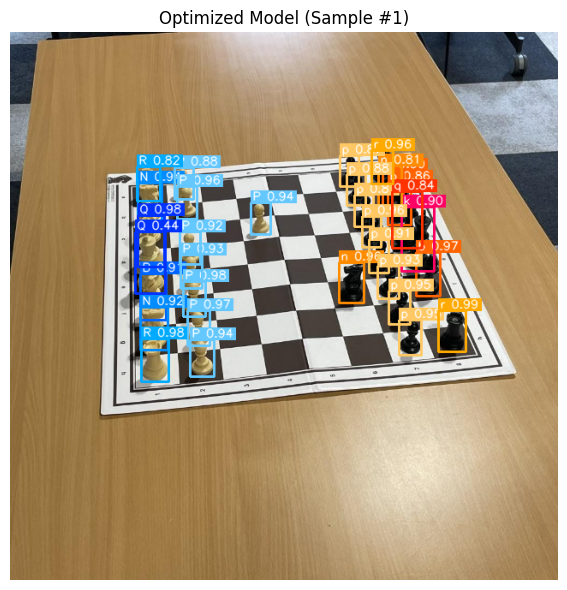

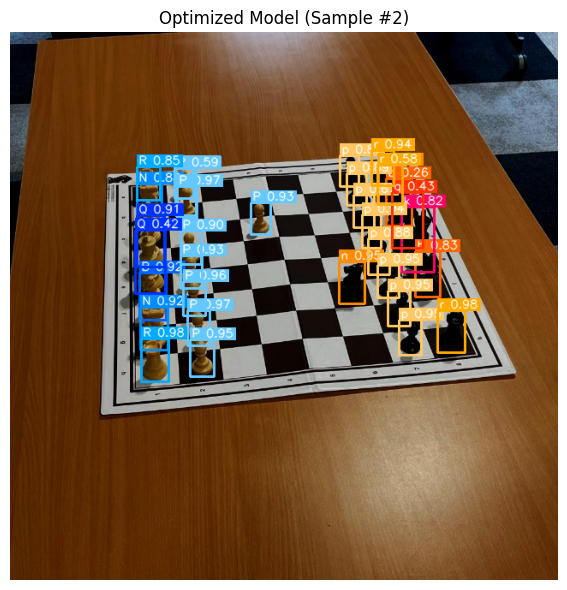

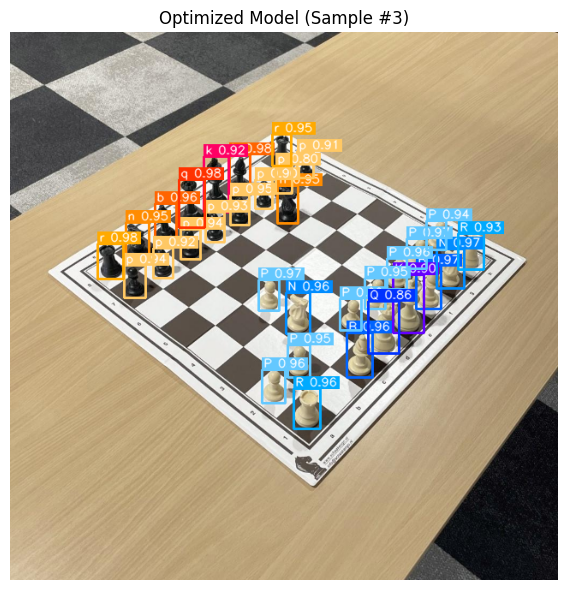

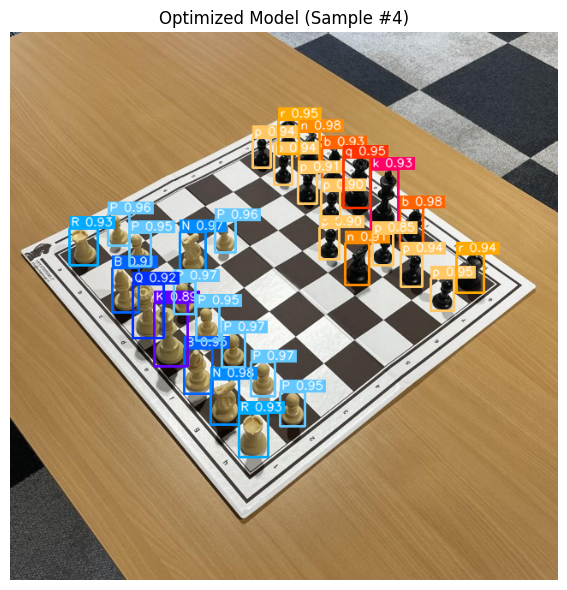

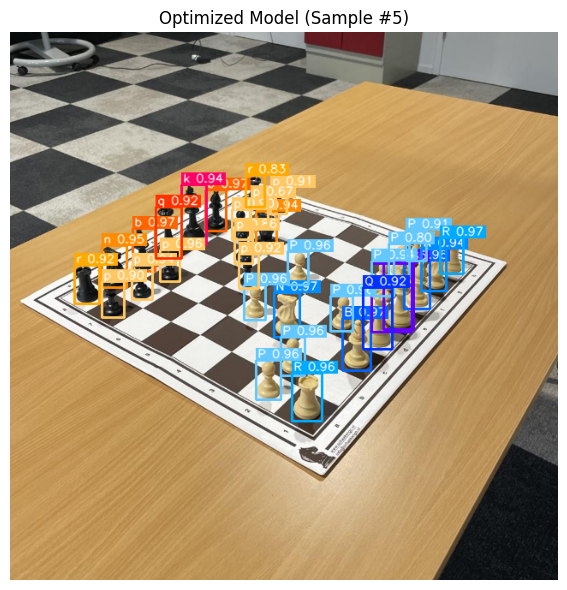

In [ ]:
assert os.path.isfile(native_model_har_path), "Please provide valid path for HAR file"
runner = ClientRunner(har=native_model_har_path)
runner.optimize_full_precision()

# Test modified full-precision model
with runner.infer_context(InferenceContext.SDK_FP_OPTIMIZED) as ctx:
    modified_res = runner.infer(ctx, calib_dataset[:IMAGES_TO_VISUALIZE, :, :, :])

fp32_detections = postproc(modified_res)
# Tích lũy kết quả qua các giai đoạn
results_history = {}

# Bước 1: Model FP32 gốc
results_history["Optimized Model"] = fp32_detections

# Hiển thị biểu đồ so sánh trực quan các bước side-by-side
saved_images = visualize_results(calib_dataset[:IMAGES_TO_VISUALIZE, :, :, :], results_history, return_history=True)

In [ ]:
optimized_model_har_path = str(hailo_working_dir/f"{model_name}_optimized_model.har")
runner.save_har(optimized_model_har_path)

### Step 4 & 5: Optimize Model, Test Accuracy & Save Quantized HAR
Run quantization with calibration dataset, verify accuracy using quantized emulator, and save quantized HAR file.

In [8]:
hn_layers = runner.get_hn_dict()["layers"]
print("Input layers are: ")
print([layer for layer in hn_layers if hn_layers[layer]["type"] == "input_layer"])  # See available input layer names

Input layers are: 
['yolo11n/input_layer1']


In [ ]:
# The original images are being used, just as the input to the SDK_FP_OPTIMIZED emulator 
calib_dataset_dict = {"yolo11n/input_layer1": calib_dataset}  # In our case there is only one input layer
assert os.path.isfile(optimized_model_har_path), "Please provide valid path for HAR file"
runner = ClientRunner(har=optimized_model_har_path)
runner.optimize(calib_dataset_dict)

[info] Starting Model Optimization
[warning] Reducing compression level to 0 because requested optimization level equal or less than 1
[info] Model received quantization params from the hn
[info] MatmulDecompose skipped
[info] Starting Mixed Precision
[info] Model Optimization Algorithm Mixed Precision is done (completion time is 00:00:00.67)
[info] LayerNorm Decomposition skipped
[info] Starting Statistics Collector
[info] Using dataset with 64 entries for calibration


Calibration: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:35<00:00,  1.82entries/s]


[info] Model Optimization Algorithm Statistics Collector is done (completion time is 00:00:36.37)
[info] Starting Fix zp_comp Encoding
[info] Model Optimization Algorithm Fix zp_comp Encoding is done (completion time is 00:00:00.00)
[info] Starting Matmul Equalization
[info] Model Optimization Algorithm Matmul Equalization is done (completion time is 00:00:00.02)
[info] Starting MatmulDecomposeFix
[info] Model Optimization Algorithm MatmulDecomposeFix is done (completion time is 00:00:00.00)
[info] activation fitting started for yolo11n/reduce_sum_softmax1/act_op
[info] Finetune encoding skipped
[info] Starting Bias Correction
[info] The algorithm Bias Correction will use up to 1.15 GB of storage space
[info] Using dataset with 64 entries for Bias Correction


2026-08-06 07:07:25.487286: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
Bias Correction: 100%|████████████████████████████████████████| 100/100 [02:54<00:00,  1.75s/blocks, Layers=['yolo11n/postprocess_output_layer']]

[info] Model Optimization Algorithm Bias Correction is done (completion time is 00:02:57.25)
[info] Adaround skipped
[info] Quantization-Aware Fine-Tuning skipped


[info] Starting Layer Noise Analysis


Full Quant Analysis: 100%|███████████████████████████████████████████████████████████████████████████████| 16/16 [01:41<00:00,  6.36s/iterations]


[info] Model Optimization Algorithm Layer Noise Analysis is done (completion time is 00:01:44.74)
[info] Model Optimization is done


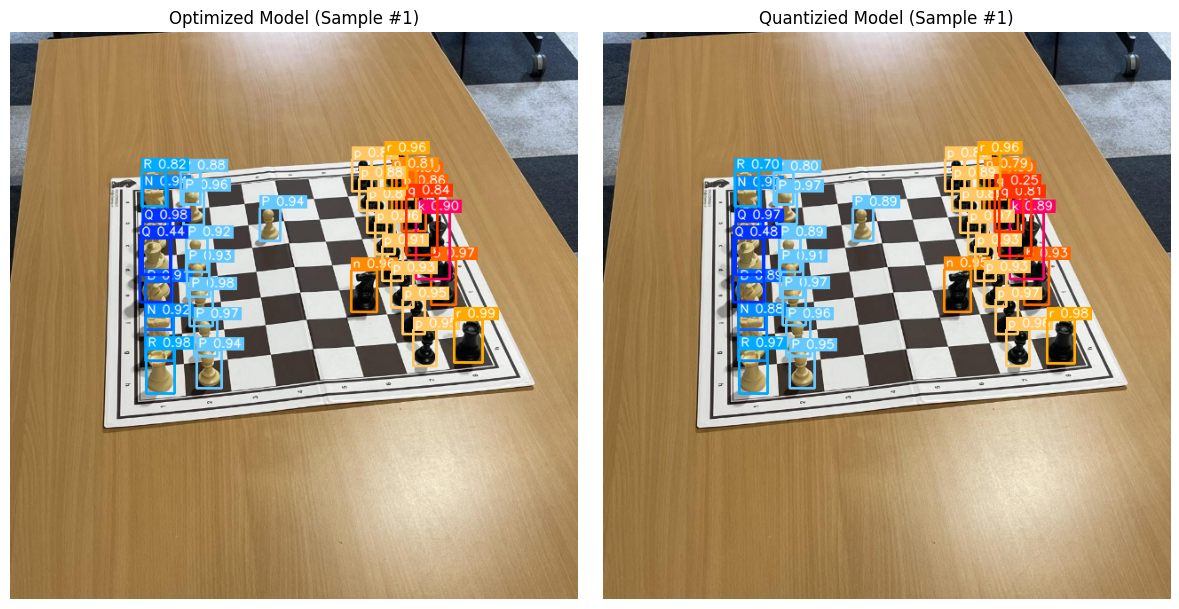

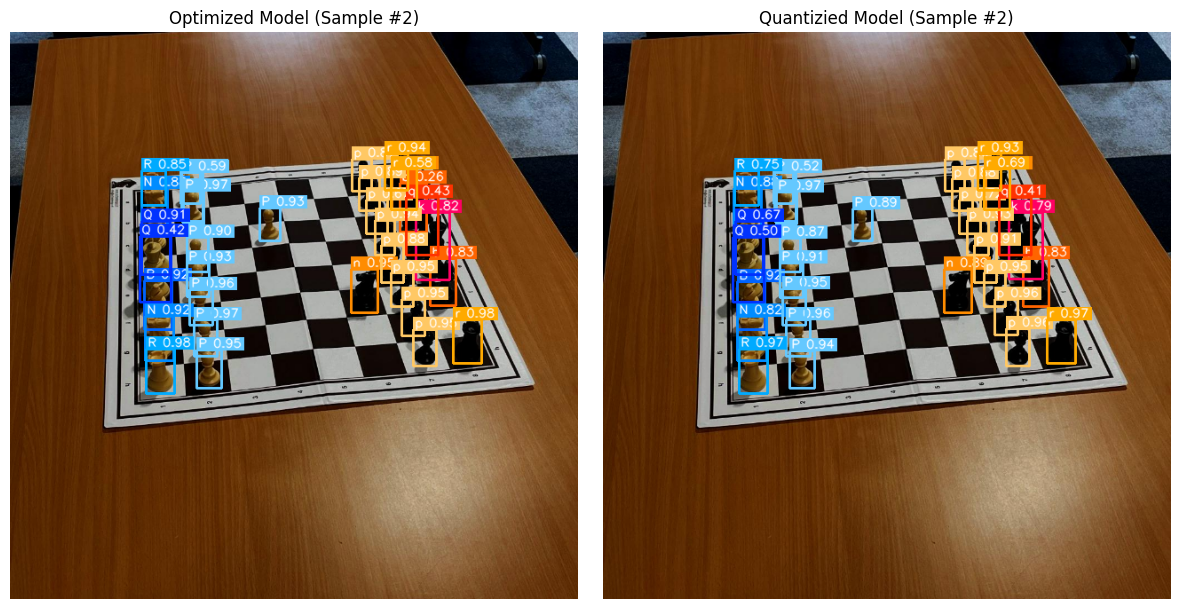

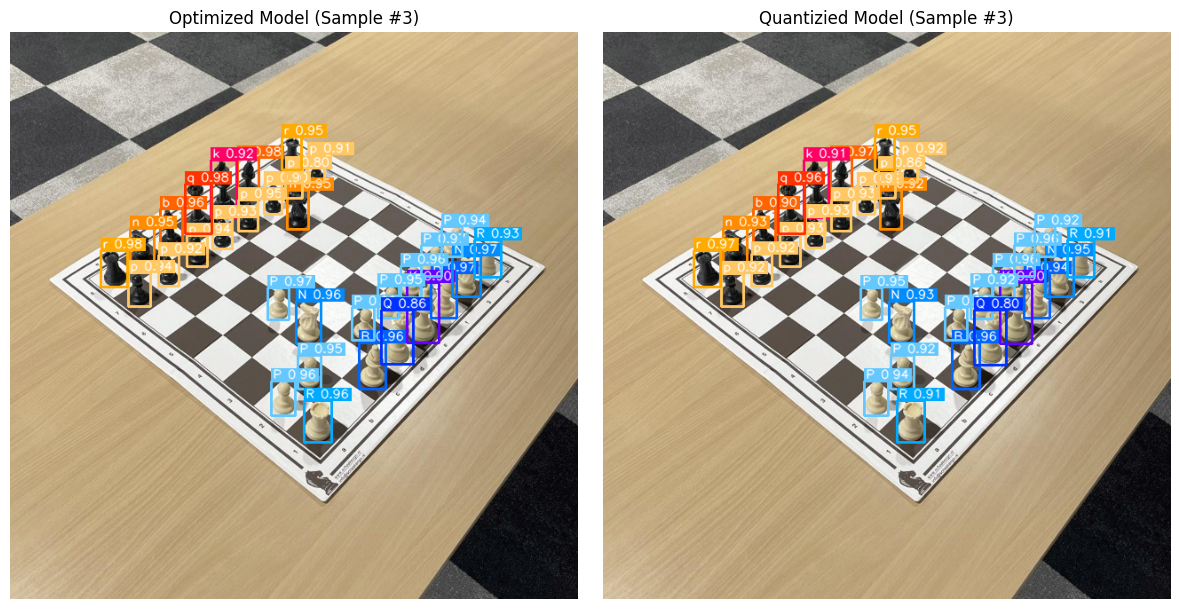

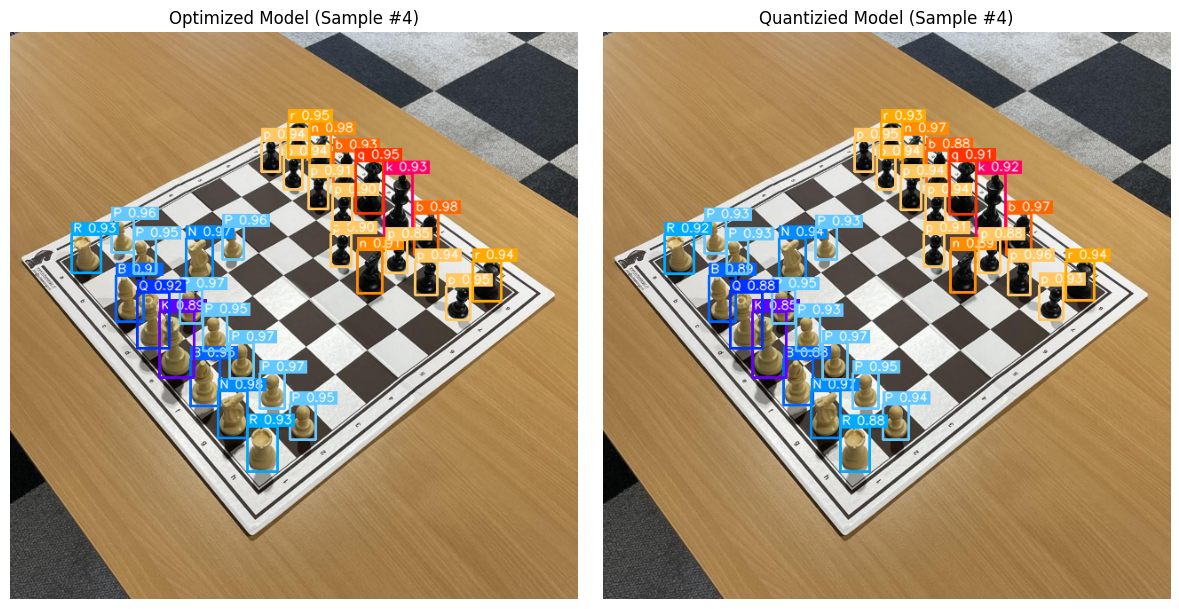

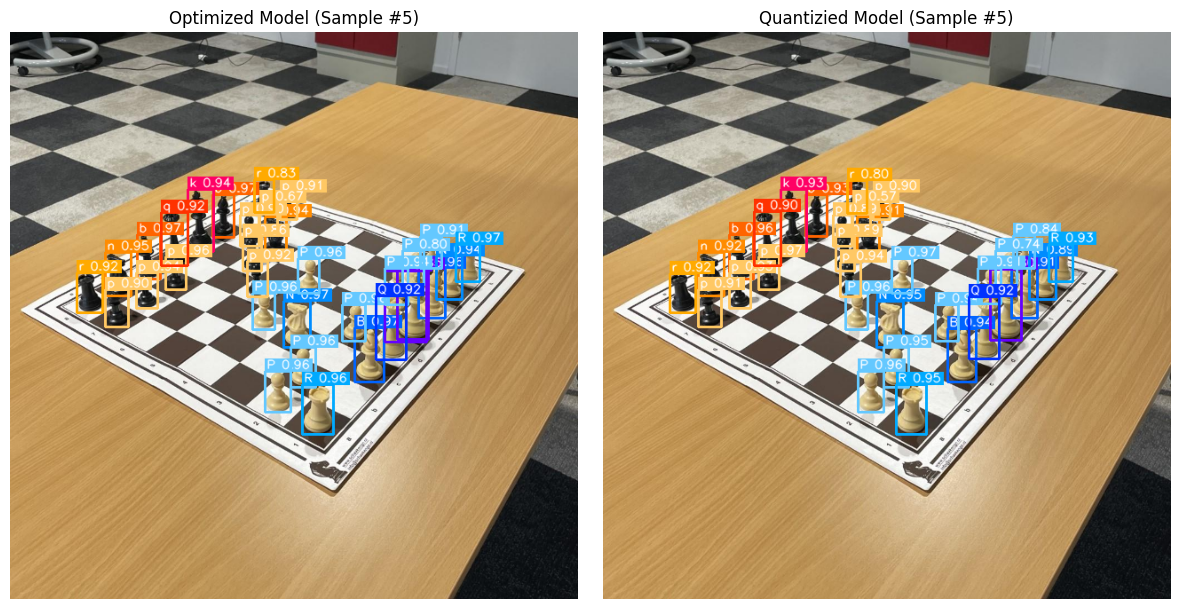

In [ ]:
# Verify quantized model accuracy
with runner.infer_context(InferenceContext.SDK_QUANTIZED) as ctx:
    quantized_res = runner.infer(ctx, calib_dataset[:IMAGES_TO_VISUALIZE, :, :, :])

int8_detections = postproc(quantized_res)
results_history["Quantizied Model"] = int8_detections

# Hiển thị biểu đồ so sánh trực quan các bước side-by-side
saved_images = visualize_results(calib_dataset[:IMAGES_TO_VISUALIZE, :, :, :], results_history, return_history=True)

In [11]:
# Save quantized HAR file
quantized_model_har_path = str(hailo_working_dir/f"{model_name}_quantized_model.har")
runner.save_har(quantized_model_har_path)

[info] Saved HAR to: /home/duykhongcay/hailo_ws/chess_pieces_detection/runs/chess_detection_yolo11n-2/hailo_chesspieces_model-2/yolo11n_quantized_model.har


### Step 6: Run Layer Noise Analysis
Analyze per-layer quantization noise (SNR) based on the quantized HAR file and plot logit SNR statistics to identify sensitive layers.

[+] Diagnostic: Inspecting SNR for target output layer -> 'yolo11n/postprocess_output_layer'


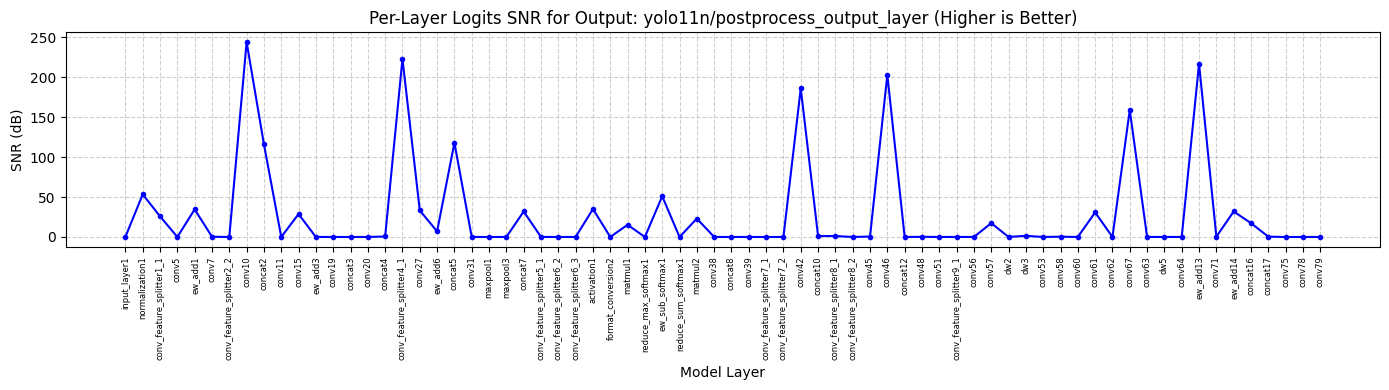

[✓] Successfully plotted SNR statistics for 70 layers.


In [6]:
def extract_snr_data(runner):
    """Dynamically extract layer noise analysis SNR statistics from runner."""
    params_stats = runner.get_params_statistics()
    hn_layers = runner.get_hn_dict()["layers"]
    output_layers = [name for name, info in hn_layers.items() if info.get("type") == "output_layer"]

    if not output_layers:
        print("[!] Warning: No output layers found in HN model.")
        return [], [], ""

    target_out_layer = output_layers[0]
    print(f"[+] Diagnostic: Inspecting SNR for target output layer -> '{target_out_layer}'")

    layers = []
    snr_list = []

    for layer in runner.get_hn_model():
        lname = layer.name
        # Possible key formats across different Hailo SDK versions
        possible_keys = [
            f"{lname}/layer_noise_analysis/{target_out_layer}",
            f"{lname}/layer_noise_analysis/noise_results/{target_out_layer}",
            f"{lname}/noise_results/{target_out_layer}",
            f"{lname}/layer_noise/{target_out_layer}",
        ]

        val = None
        for k in possible_keys:
            if k in params_stats:
                val = params_stats[k]
                break

        # Fallback: search key dynamically by matching substrings
        if val is None:
            for k, v in params_stats.items():
                if lname in k and ("noise" in k or "snr" in k):
                    val = v
                    break

        if val is not None:
            try:
                # Convert scalar or numpy array to float value safely
                if isinstance(val, (list, np.ndarray)) and len(val) > 0:
                    snr_val = float(val[0])
                else:
                    snr_val = float(val)

                layers.append(layer.name_without_scope)
                snr_list.append(snr_val)
            except Exception:
                continue

    return layers, snr_list, target_out_layer

assert os.path.isfile(quantized_model_har_path), "Please provide valid path for HAR file"
runner = ClientRunner(har= quantized_model_har_path)
# Extract SNR results dynamically
layers, snr, target_layer = extract_snr_data(runner)

# Plot SNR graph
if layers and snr:
    plt.figure(figsize=(14, 4))
    plt.plot(layers, snr, marker='o', linestyle='-', color='b', markersize=3)
    plt.title(f"Per-Layer Logits SNR for Output: {target_layer} (Higher is Better)")
    plt.xlabel("Model Layer")
    plt.ylabel("SNR (dB)")
    plt.xticks(rotation=90, fontsize=6)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
    print(f"[✓] Successfully plotted SNR statistics for {len(layers)} layers.")
else:
    print("[!] Could not locate SNR statistics keys in params_statistics.")
    print("[!] Sample available keys in params_statistics for debugging:")
    stats_keys = list(runner.get_params_statistics().keys())
    for key in stats_keys[:10]:
        print(f"  - {key}")


### Step 7: Compile Quantized HAR File to HEF & Save Compiled HAR
Compile the quantized HAR file into an executable .hef file and save the compiled HAR file for profiling.

In [ ]:

# Compile quantized HAR file to HEF
assert os.path.isfile(quantized_model_har_path), "Please provide valid path for HAR file"
runner = ClientRunner(har=quantized_model_har_path)
hef = runner.compile()
hef_path = str(hailo_working_dir/f"{model_name}.hef")
with open(hef_path, "wb") as f:
    f.write(hef)

# Save compiled HAR file
compiled_model_har_path = str(hailo_working_dir/f"{model_name}_compiled_model.har")
runner.save_har(compiled_model_har_path)
print(f"Compiled HEF saved to {hef_path}")
print(f"Compiled HAR saved to {compiled_model_har_path}")

# CLI equivalent command reference:
# !hailo compiler {quantized_model_har_path} --hw-arch hailo8 --output-dir . --output-har-path {compiled_model_har_path}


ModuleNotFoundError: No module named 'hailo_sdk_client.sdk_backend.sdk_paths'

### Step 8: Run Hardware  & Export runtime_data.json
Measure firmware runtime actions using hailortcli on device/host PC, or execute hardware inference context.

In [ ]:
# Execute hailortcli on edge device to record runtime JSON
!hailortcli run2 -m raw measure-fw-actions --output-path {runtime_data_path} set-net {hef_path}

/usr/bin/sh: 1: hailortcli: not found


### Step 9: Generate HTML Profiler Report
Combine compiled HAR file and runtime_data.json to generate an HTML profiler report.

In [10]:
# Generate visual HTML profiler report
profiler_html_path = str(hailo_working_dir/f"{model_name}_runtime_profiler.html")
!hailo profiler {compiled_model_har_path} --runtime-data {runtime_data_path} --out-path {profiler_html_path}
print(f"Profiler HTML report generated: {profiler_html_path}")


E0000 00:00:1786006722.992807    1151 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1786006722.997598    1151 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
[info] Current Time: 08:58:47, 08/06/26
[info] CPU: Architecture: x86_64, Model: AMD Ryzen 7 5800H with Radeon Graphics, Number Of Cores: 16, Utilization: 1.6%
[info] Memory: Total: 15GB, Available: 11GB
[info] System info: OS: Linux, Kernel: 7.0.0-28-generic
[info] Hailo DFC Version: 3.34.0
[info] HailoRT Version: Not Installed
[info] PCIe: No Hailo PCIe device was found
[info] Running `hailo profiler /home/duykhongcay/hailo_ws/chess_pieces_detection/runs/chess_detection_yolo11n-2/hailo_chesspieces_model-2/yolo11n_compiled_model.har --runtime-data /home/duykhongcay/hailo_ws/chess_pieces_detection/runs/chess_detection_yolo11n-2/hailo_chess